# Healthcare Analytics for Doctor Visits
**DIY Data Analytics Project**

Objective: explore how reported illnesses, health indicators, age, income and healthcare support relate to the number of doctor visits. This is descriptive analysis, not medical advice or causal proof.

## 1. Import libraries and load data

## 1. Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('doctor_visits.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'doctor_visits.csv'

## 2. Understand the dataset

In [ ]:
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
df.info()
df.isna().sum()

Shape: (5190, 13)
Columns: ['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


Unnamed: 0    0
visits        0
gender        0
age           0
income        0
illness       0
reduced       0
health        0
private       0
freepoor      0
freerepat     0
nchronic      0
lchronic      0
dtype: int64

The `Unnamed: 0` field is a record identifier, so it is excluded from analytical summaries. The `age` values are stored on a fractional scale in this dataset; do not interpret them as years without additional metadata.

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,5190.0,NaN,NaN,NaN,2595.5,1498.368279,1.0,1298.25,2595.5,3892.75,5190.0
visits,5190.0,NaN,NaN,NaN,0.301734,0.798134,0.0,0.0,0.0,0.0,9.0
gender,5190,2,female,2702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5190.0,NaN,NaN,NaN,0.406385,0.204782,0.19,0.22,0.32,0.62,0.72
income,5190.0,NaN,NaN,NaN,0.58316,0.368907,0.0,0.25,0.55,0.9,1.5
illness,5190.0,NaN,NaN,NaN,1.431985,1.384152,0.0,0.0,1.0,2.0,5.0
reduced,5190.0,NaN,NaN,NaN,0.86185,2.887628,0.0,0.0,0.0,0.0,14.0
health,5190.0,NaN,NaN,NaN,1.217534,2.124266,0.0,0.0,0.0,2.0,12.0
private,5190,2,no,2892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freepoor,5190,2,no,4968,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Prepare data

In [ ]:
data = df.drop(columns=['Unnamed: 0']).copy()
print('Duplicate rows:', data.duplicated().sum())
print('Missing values:', data.isna().sum().sum())
data['age_group'] = pd.cut(data['age'], bins=[0, 0.25, 0.35, 0.50, 0.75], labels=['Up to 0.25', '0.26–0.35', '0.36–0.50', 'Above 0.50'], include_lowest=True)
data.head()

Duplicate rows: 1320
Missing values: 0


,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic,age_group
0,1,female,0.19,0.55,1,4,1,yes,no,no,no,no,Up to 0.25
1,1,female,0.19,0.45,1,2,1,yes,no,no,no,no,Up to 0.25
2,1,male,0.19,0.90,3,0,0,no,no,no,no,no,Up to 0.25
3,1,male,0.19,0.15,1,0,0,no,no,no,no,no,Up to 0.25
4,1,male,0.19,0.45,2,5,1,no,no,no,yes,no,Up to 0.25


## 4. Key indicators

In [ ]:
print(f"Records: {len(data):,}")
print(f"Average visits: {data['visits'].mean():.3f}")
print(f"Median visits: {data['visits'].median():.0f}")
print(f"Records with zero visits: {(data['visits'].eq(0).mean()*100):.1f}%")
print(f"Records with one or more visits: {(data['visits'].gt(0).mean()*100):.1f}%")
print('Visit count distribution:')
display(data['visits'].value_counts().sort_index().rename_axis('visits').to_frame('records'))

Records: 5,190
Average visits: 0.302
Median visits: 0
Records with zero visits: 79.8%
Records with one or more visits: 20.2%
Visit count distribution:


,records
visits,
0,4141
1,782
2,174
3,30
4,24
5,9
6,12
7,12
8,5


## 5. Visual analysis

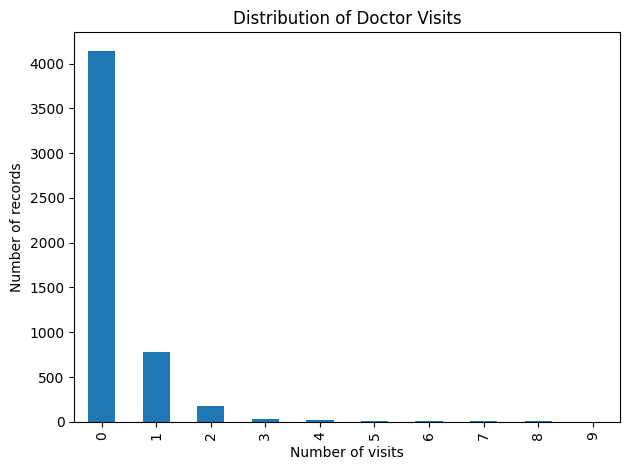

In [ ]:
counts = data['visits'].value_counts().sort_index()
counts.plot(kind='bar', title='Distribution of Doctor Visits', xlabel='Number of visits', ylabel='Number of records')
plt.tight_layout(); plt.show()

,illness,count,mean
0,0,1554,0.078507
1,1,1638,0.295482
2,2,946,0.403805
3,3,542,0.420664
4,4,274,0.576642
5,5,236,0.813559


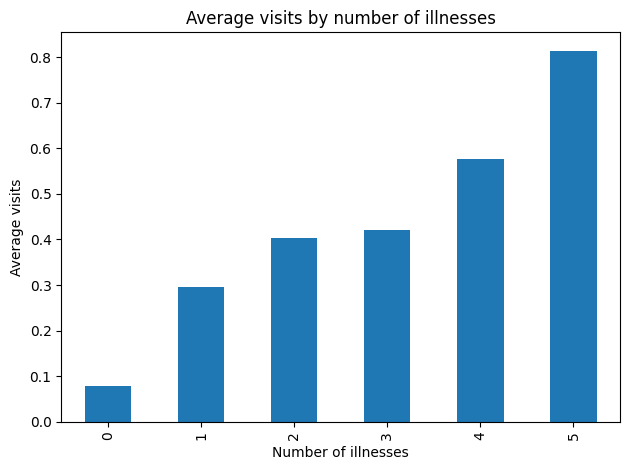

In [ ]:
illness_summary = data.groupby('illness')['visits'].agg(['count','mean']).reset_index()
display(illness_summary)
illness_summary.plot(x='illness', y='mean', kind='bar', legend=False, title='Average visits by number of illnesses', xlabel='Number of illnesses', ylabel='Average visits')
plt.tight_layout(); plt.show()

,nchronic,count,mean
0,no,3098,0.272111
1,yes,2092,0.345602


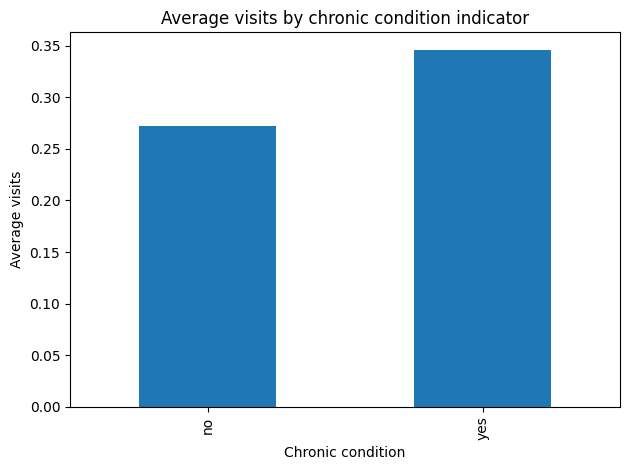

In [ ]:
chronic_summary = data.groupby('nchronic')['visits'].agg(['count','mean']).reset_index()
display(chronic_summary)
chronic_summary.plot(x='nchronic', y='mean', kind='bar', legend=False, title='Average visits by chronic condition indicator', xlabel='Chronic condition', ylabel='Average visits')
plt.tight_layout(); plt.show()

,gender,count,mean
0,female,2702,0.361954
1,male,2488,0.236334


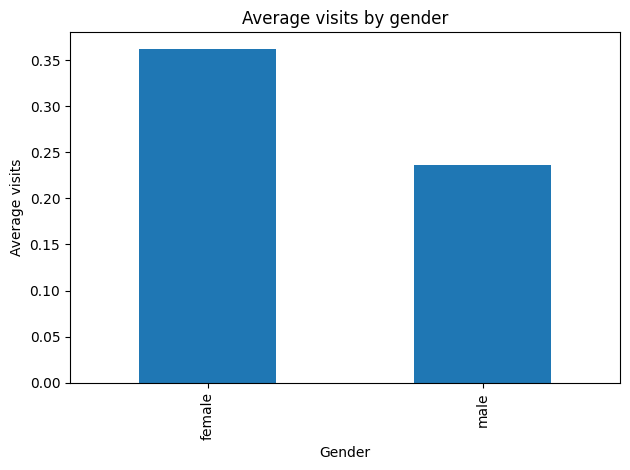

In [ ]:
gender_summary = data.groupby('gender')['visits'].agg(['count','mean']).reset_index()
display(gender_summary)
gender_summary.plot(x='gender', y='mean', kind='bar', legend=False, title='Average visits by gender', xlabel='Gender', ylabel='Average visits')
plt.tight_layout(); plt.show()

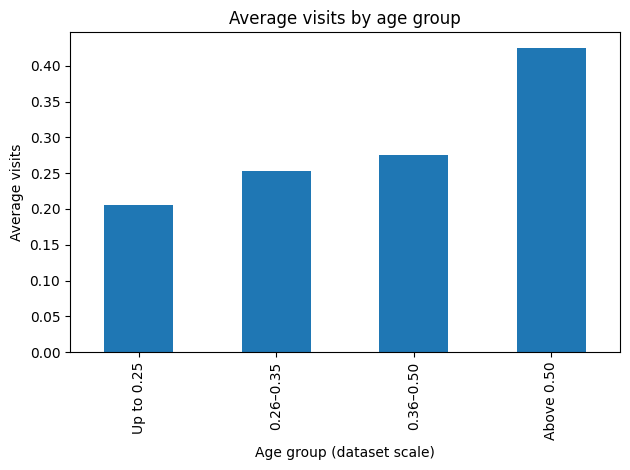

In [ ]:
data.groupby('age_group', observed=False)['visits'].agg(['count','mean']).plot(y='mean', kind='bar', legend=False, title='Average visits by age group', xlabel='Age group (dataset scale)', ylabel='Average visits')
plt.tight_layout(); plt.show()

## 6. Correlation check

In [ ]:
corr = data[['visits','age','income','illness','reduced','health']].corr()
display(corr['visits'].sort_values(ascending=False).to_frame('correlation_with_visits'))


,correlation_with_visits
visits,1.000000
reduced,0.418954
illness,0.223552
health,0.193272
age,0.124537
income,-0.076840


## 7. Summary and limitations
Use the observed group averages and plots to describe associations. The dataset is observational, so these patterns do not establish that a factor causes more visits. Age is stored as a fractional scale, and its exact interpretation should be confirmed from full dataset documentation. The dataset is not a substitute for clinical guidance.